# Approximating pRF Fits of the Natural Scenes Dataset (NSD) in V2 with Henderson's Log-Polar pRF Grid
In this notebook, we take the population receptive field (pRF) fits from the Natural Scenes Dataset (NSD) and approximate them on the log-polar grid introduced in Henderson (2023) for their texture model.

The workflow is as follows:
1.   Convert the NSD pRF fits into Cartesian coordinates (𝑥, 𝑦, 𝜎)
2.   Map each voxel onto the closest-matching pRF on the Henderson grid by:
  *   Using Euclidean distance to find the nearest position match
  *   Applying intersection-over-union (IoU) to select the best-matching receptive field size.




# Setup dependencies for visualizing pRFs



### After running the first cell, notebook automatically restarts. Don't run it again. This setup is necessary for the visualization part.

In [1]:
! pip install -q ipympl
get_ipython().kernel.do_shutdown(restart=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.0/519.0 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 15.6 MB/s eta 0:00:00


{'status': 'ok', 'restart': True}

In [ ]:
! pip install ipywidgets

In [ ]:
%matplotlib widget

In [ ]:
from google.colab import output
output.enable_custom_widget_manager()

# Import libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import nibabel as nib
import numpy as np
import sys
import pandas as pd
import numpy as np
sys.path.extend(['/content/drive/MyDrive/V2_drift/texturemodel/code',
                '/content/drive/MyDrive/V2_drift/texturemodel/code/utils']
                )
from model_fitting import initialize_fitting
from prf_utils import pol_to_cart
from roi_utils import get_voxel_retino_info, get_voxel_roi_info
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.widgets import Slider
import matplotlib.gridspec as gridspec
from ipywidgets import Text, HBox, Output
from IPython.display import display
import os

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Define utility functions

In [ ]:
def size_to_sigma(size, exponent):
  sigma = size * np.sqrt(exponent)
  return sigma

In [ ]:
def make_log_polar_grid(sigma_range=[0.02, 1], n_sigma_steps=10,
                        eccen_range=[0, 7/8.4], n_eccen_steps=10, n_angle_steps=16):
    sigma_vals = np.logspace(np.log(sigma_range[0]), np.log(sigma_range[1]),
                             base=np.e, num=n_sigma_steps)
    small_value = 0.10
    eccen_vals = np.logspace(np.log(eccen_range[0]+small_value), np.log(eccen_range[1]+small_value),
                             base=np.e, num=n_eccen_steps) - small_value
    angle_step = 2 * np.pi / n_angle_steps
    angle_vals = np.linspace(0, 2 * np.pi - angle_step, n_angle_steps)

    eccen_vals = eccen_vals.astype(np.float32)
    angle_vals = angle_vals.astype(np.float32)
    sigma_vals = sigma_vals.astype(np.float32)

    x_vals = eccen_vals[:, np.newaxis] * np.cos(angle_vals[np.newaxis, :])
    y_vals = eccen_vals[:, np.newaxis] * np.sin(angle_vals[np.newaxis, :])

    x_vals = np.tile(np.reshape(x_vals, [n_angle_steps * n_eccen_steps, 1]), [n_sigma_steps, 1])
    y_vals = np.tile(np.reshape(y_vals, [n_angle_steps * n_eccen_steps, 1]), [n_sigma_steps, 1])
    sigma_vals = np.repeat(sigma_vals, n_angle_steps * n_eccen_steps)[:, np.newaxis]

    prf_params = np.concatenate([x_vals, y_vals, sigma_vals], axis=1)
    _, inds = np.unique(prf_params, axis=0, return_index=True)
    prf_params = prf_params[np.sort(inds), :]

    n_std = 1
    left_extent = prf_params[:, 0] - prf_params[:, 2] * n_std
    right_extent = prf_params[:, 0] + prf_params[:, 2] * n_std
    top_extent = prf_params[:, 1] + prf_params[:, 2] * n_std
    bottom_extent = prf_params[:, 1] - prf_params[:, 2] * n_std

    out_of_bounds = (left_extent > 0.5) | (right_extent < -0.5) | \
                    (top_extent < -0.5) | (bottom_extent > 0.5)
    prf_params = prf_params[~out_of_bounds, :]

    return prf_params

# Set up log-polar grid

In [ ]:
def compute_circle_iou(x1, y1, r1, x2, y2, r2):
    """
    Compute the IoU of two circles.
    """
    d = np.sqrt((x1 - x2)**2 + (y1 - y2)**2)

    if d >= r1 + r2:
        return 0.0  # No overlap

    if d <= abs(r1 - r2):
        # One fully inside the other
        return (min(np.pi * r1**2, np.pi * r2**2)) / (np.pi * max(r1**2, r2**2))

    # Partial overlap — compute using circle intersection area formula
    part1 = r1**2 * np.arccos((d**2 + r1**2 - r2**2) / (2 * d * r1))
    part2 = r2**2 * np.arccos((d**2 + r2**2 - r1**2) / (2 * d * r2))
    part3 = 0.5 * np.sqrt((-d + r1 + r2) * (d + r1 - r2) *
                          (d - r1 + r2) * (d + r1 + r2))
    intersection = part1 + part2 - part3
    union = np.pi * r1**2 + np.pi * r2**2 - intersection
    return intersection / union



def find_best_overlap_prf(x, y, sigma_q):
    """
    Find the best matching pRF based on IoU overlap with a custom pRF.
    """
    best_iou = -1
    best_idx = -1
    for i in range(len(x_positions)):
        iou = compute_circle_iou(x, y, sigma_q, x_positions[i], y_positions[i], sigmas[i])
        if iou > best_iou:
            best_iou = iou
            best_idx = i
    return best_idx, best_iou



prf_params = make_log_polar_grid()
x_positions = prf_params[:, 0]
y_positions = prf_params[:, 1]
sigmas = prf_params[:, 2]


# Optional: Visualize and test our pRF matching algorithm on Maggie's grid.
### Try entering sample x, y, and sigma values.

In [ ]:
# @title
def create_zoomable_scatter_plot(x_positions, y_positions, sigma_values):
    fig = plt.figure(figsize=(8, 8))
    gs = gridspec.GridSpec(2, 1, height_ratios=[9, 1])

    ax_main = fig.add_subplot(gs[0])
    ax_control = fig.add_subplot(gs[1])
    zoom_min, zoom_max = 0.05, 1.0
    initial_zoom = 0.75

    sizes = 20 + 100 * (sigma_values - min(sigma_values)) / (max(sigma_values) - min(sigma_values))
    scatter = ax_main.scatter(x_positions, y_positions)

    ax_main.set_xlim(-initial_zoom, initial_zoom)
    ax_main.set_ylim(-initial_zoom, initial_zoom)
    ax_main.set_xlabel("X Position")
    ax_main.set_ylabel("Y Position")
    ax_main.set_title("pRF Grid\n(1600 candidate pRFs: 16 angles × 10 eccentricities × 10 sizes)")
    ax_main.grid(True, alpha=0.3)
    ax_main.set_aspect('equal')

    # Zoom slider
    ax_zoom = plt.axes([0.2, 0.12, 0.65, 0.03])
    zoom_slider = Slider(ax=ax_zoom, label='Zoom', valmin=zoom_min, valmax=zoom_max, valinit=initial_zoom)

    def update_zoom(val):
        visible_radius = zoom_max - zoom_slider.val + zoom_min
        ax_main.set_xlim(-visible_radius, visible_radius)
        ax_main.set_ylim(-visible_radius, visible_radius)
        fig.canvas.draw_idle()

    zoom_slider.on_changed(update_zoom)

    # Custom point + circle
    custom_point, = ax_main.plot([], [], 'rx', markersize=10, label='Custom pRF Center')
    custom_circle = Circle((0, 0), radius=0.0, edgecolor='red', fill=False, linestyle='--', linewidth=2)
    ax_main.add_patch(custom_circle)
    # Best match circle (blue)
    best_circle = Circle((0, 0), radius=0.0, edgecolor='green', fill=False, linestyle='--', linewidth=2)
    ax_main.add_patch(best_circle)

    # Best match point
    best_point, = ax_main.plot([], [], 'go', markersize=10, label='Best Matching pRF')
    best_text = ax_main.text(0, 0, '', color='green', fontsize=9, ha='right', va='bottom')

    ax_main.legend(loc='upper right')

    return fig, ax_main, zoom_slider, custom_point, custom_circle, best_circle, best_point, best_text





def update_point(change=None):
    with out:
        x_val = x_input.value.strip()
        y_val = y_input.value.strip()
        sigma_val = sigma_input.value.strip()

        if not x_val or not y_val or not sigma_val:
            custom_point.set_data([], [])
            custom_circle.set_radius(0.0)
            best_point.set_data([], [])
            best_text.set_text('')
            fig.canvas.draw_idle()
            return

        try:
            x = float(x_val)
            y = float(y_val)
            sigma = float(sigma_val)

            custom_point.set_data([x], [y])
            custom_circle.center = (x, y)
            custom_circle.set_radius(sigma)

            idx, strength = find_best_overlap_prf(x, y, sigma)
            bx, by, bsigma = x_positions[idx], y_positions[idx], sigmas[idx]

            best_point.set_data([bx], [by])
            best_circle.center = (bx, by)
            best_circle.set_radius(bsigma)
            best_text.set_position((bx, by))
            best_text.set_text(f"Best pRF\n({bx:.3f}, {by:.3f})\nσ={bsigma:.3f}\nIOU={strength:.3f}")


            fig.canvas.draw_idle()
        except ValueError:
            print("Invalid input.")

Output()

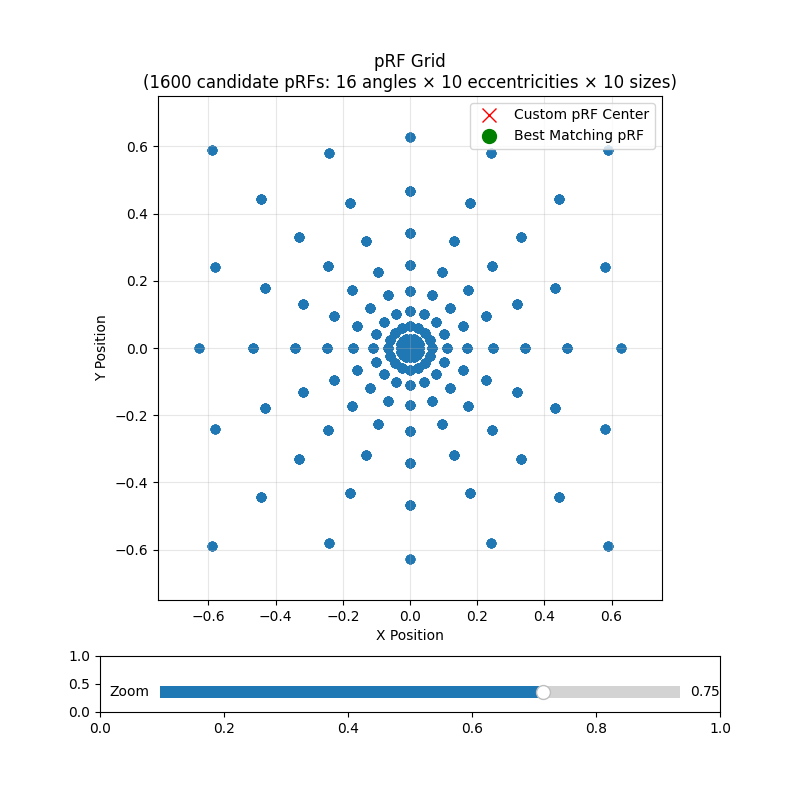

In [ ]:
# @title

fig, ax, slider, custom_point, custom_circle, best_circle, best_point, best_text = create_zoomable_scatter_plot(
    x_positions, y_positions, sigmas)

x_input = Text(value='', description='X:')
y_input = Text(value='', description='Y:')
sigma_input = Text(value='', description='σ:')
out = Output()

x_input.observe(update_point, names='value')
y_input.observe(update_point, names='value')
sigma_input.observe(update_point, names='value')

update_point()

display(HBox([x_input, y_input, sigma_input]))
display(out)
plt.show()


# Process NSD Fits

# Initialize mappings

In [ ]:
subject_list = [2]   # later: [1,2,3,4,5,6,7,8]
roi_name = 'V1'      # later change to 'V1', 'V2', 'V3', or 'hV4'

mapping = {1: "V1v", 2: "V1d", 3: "V2v", 4: "V2d", 5: "V3v", 6: "V3d", 7: "hV4"}
all_subjects_data = {}
roi_transformed_dict = {}

# Convert NSD fits to Cartesian coordinates.

### *Get voxel indices of ROI.*
In this example, we get the voxel indices of V2 for subject 1. But this code can work for all other subjects and retinotopic ROIs (V1-hV4).

### *UPDATED:*
Instead of hardcoding path to preprocessed indices, I called a new function which returns the indices of an ROI of a subject. This works for all subjects and all retinotopic ROIS (V1-hV4). For example, if I want to get the ROI indices of V2 in subject 1, we run the following function like so:

In [ ]:
### OLD WAY
# roi_indices = np.load('/content/drive/MyDrive/roi_indices.npy')  # full‐brain flat indices

In [ ]:
# ── BUILD & CONVERT ROI COORDINATES (to CARTESIAN FORM) ─────────────────────────

for subj in subject_list:

    print(f"\nProcessing subject {subj}, ROI {roi_name}")

    # Get ROI indices for this subject and ROI
    roi_indices = get_voxel_retino_info(subj, load_preproc=False, roi=roi_name)[1][0]

    # Reset per subject
    roi_transformed = []

    # File paths
    base_path = f'/content/drive/MyDrive/V1_Drift/NSD/subj{str(subj).zfill(2)}/func1pt8mm/'

    # Load and flatten all necessary data
    paths = {
        'size': f'{base_path}prf_size.nii.gz',
        'eccentricity': f'{base_path}prf_eccentricity.nii.gz',
        'angle': f'{base_path}prf_angle.nii.gz',
        'exponent': f'{base_path}prf_exponent.nii.gz',
        'rois': f'{base_path}roi/prf-visualrois.nii.gz'
    }

    flattened = {key: nib.load(path).get_fdata().flatten() for key, path in paths.items()}
    flattened['rois'] = flattened['rois'].astype(int)

    # Convert each voxel to (x, y, sigma)
    for idx in roi_indices:
        x, y = pol_to_cart(
            flattened['angle'][idx],
            flattened['eccentricity'][idx]
        )

        x /= 8.4
        y /= 8.4

        sigma = size_to_sigma(
            flattened['size'][idx],
            flattened['exponent'][idx]
        ) / 8.4

        roi_transformed.append((x, y, sigma))

    print("Number of voxels processed:", len(roi_transformed))


Processing subject 2, ROI V1
Number of voxels processed: 1630


In [ ]:
 # ── ALIGN & SORT INDICES + COORDS ──────────────────────────────────────────────
# zip them together, sort by the original index, then discard the indices
sorted_pairs = sorted(zip(roi_indices, roi_transformed),
                      key=lambda pair: pair[0])

merged_dict = {
    roi_name: np.array([coord for _, coord in sorted_pairs])
}

assert merged_dict[roi_name].shape[0] == len(roi_indices), \
    f"Expected {len(roi_indices)} {roi_name} voxels, but got {merged_dict[roi_name].shape[0]}"

# Compare NSD vs. Maggie's fits visually



In [ ]:
if roi_name == "V2" and subj == 1:
    maggies_fits = np.load(
        '/content/drive/MyDrive/V2_drift/prf_indices/subj01_best_prf_tuples_V2.npy',
        allow_pickle=True
    )

    maggie_coords = np.array([row[2].squeeze() for row in maggies_fits])
    roi_coords = np.array(roi_transformed)

    assert maggie_coords.shape == roi_coords.shape

    plt.figure(figsize=(8, 8))
    plt.scatter(maggie_coords[:, 0], maggie_coords[:, 1], label='Maggie Fits', alpha=0.5, s=10)
    plt.scatter(roi_coords[:, 0], roi_coords[:, 1], label=f'Transformed ROI {roi_name}', alpha=0.5, s=10)
    plt.legend()
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'pRF Center Comparison: Subject {subj}, {roi_name}')
    plt.grid(True)
    plt.axis('equal')
    plt.show()

# Find best-matching pRF indices

In [ ]:
# ── FIND BEST pRF INDEXES FOR ROI ─────────────────────────────────────────────────
best_prf_indices = []
for (x, y, s) in merged_dict[roi_name]:
    best_prf_indices.append([find_best_overlap_prf(x, y, s)[0]]) # >>> This is the function that finds the pRF index of Maggie's grid the has the greatest overlap with the NSD-fit pRF.
best_prf_indices = np.array(best_prf_indices)

In [ ]:
# check outputs
print(best_prf_indices.shape)
print(np.isnan(best_prf_indices).any())
print(best_prf_indices.min(), best_prf_indices.max())

(1791, 1)
False
0 1445


# Save best-matching pRF indices (to be used for model fitting)

In [ ]:
# ── Save BEST pRF INDEXES for region ─────────────────────────────────────────────────

save_path = (
    f'/content/drive/MyDrive/V2_drift/prf_indices/'
    f'subj{str(subj).zfill(2)}_normalized_final_best_prf_indices_{roi_name}.npy'
)
os.makedirs(os.path.dirname(save_path), exist_ok=True)
np.save(save_path, best_prf_indices)
print(f"Saved best_prf_indices for subject {subj}, ROI {roi_name}, to {save_path}")

Saved best_prf_indices for subject 2, ROI V1, to /content/drive/MyDrive/V2_drift/prf_indices/subj02_normalized_final_best_prf_indices_V1.npy


# run on all subejct all rois

In [ ]:
import os
import numpy as np
import nibabel as nib

subject_list = [1, 2, 3, 4, 5, 6, 7, 8]
roi_list = ['V1', 'V2', 'V3', 'hV4']

mapping = {
    1: "V1v", 2: "V1d",
    3: "V2v", 4: "V2d",
    5: "V3v", 6: "V3d",
    7: "hV4"
}

save_dir = '/content/drive/MyDrive/V2_drift/prf_indices'
os.makedirs(save_dir, exist_ok=True)

for subj in subject_list:
    print(f"\n{'='*60}")
    print(f"Subject {subj}")
    print(f"{'='*60}")

    # File paths
    base_path = f'/content/drive/MyDrive/V1_Drift/NSD/subj{str(subj).zfill(2)}/func1pt8mm/'
    paths = {
        'size': f'{base_path}prf_size.nii.gz',
        'eccentricity': f'{base_path}prf_eccentricity.nii.gz',
        'angle': f'{base_path}prf_angle.nii.gz',
        'exponent': f'{base_path}prf_exponent.nii.gz',
        'rois': f'{base_path}roi/prf-visualrois.nii.gz'
    }

    # Load once per subject
    flattened = {key: nib.load(path).get_fdata().flatten() for key, path in paths.items()}
    flattened['rois'] = flattened['rois'].astype(int)

    for roi_name in roi_list:
        print(f"\nProcessing subject {subj}, ROI {roi_name}")

        # Get ROI voxel indices
        roi_indices = get_voxel_retino_info(
            subj,
            load_preproc=False,
            roi=roi_name
        )[1][0]

        if len(roi_indices) == 0:
            print(f"Skipping {roi_name}: no voxels found")
            continue

        roi_transformed = []

        # Convert each voxel to (x, y, sigma)
        for idx in roi_indices:
            x, y = pol_to_cart(
                flattened['angle'][idx],
                flattened['eccentricity'][idx]
            )

            x /= 8.4
            y /= 8.4

            sigma = size_to_sigma(
                flattened['size'][idx],
                flattened['exponent'][idx]
            ) / 8.4

            roi_transformed.append((x, y, sigma))

        print("Number of voxels processed:", len(roi_transformed))

        # Sort by original voxel index
        sorted_pairs = sorted(zip(roi_indices, roi_transformed), key=lambda pair: pair[0])
        merged_coords = np.array([coord for _, coord in sorted_pairs])

        assert merged_coords.shape[0] == len(roi_indices), (
            f"Expected {len(roi_indices)} {roi_name} voxels, "
            f"but got {merged_coords.shape[0]}"
        )

        # Find best pRF index for each voxel
        best_prf_indices = []
        for (x, y, s) in merged_coords:
            best_idx = find_best_overlap_prf(x, y, s)[0]
            best_prf_indices.append([best_idx])

        best_prf_indices = np.array(best_prf_indices)

        # Save
        save_path = os.path.join(
            save_dir,
            f'subj{str(subj).zfill(2)}_normalized_final_best_prf_indices_{roi_name}.npy'
        )
        np.save(save_path, best_prf_indices)

        print(f"Saved: {save_path}")
        print(f"Shape: {best_prf_indices.shape}")


Subject 1

Processing subject 1, ROI V1
Number of voxels processed: 2392


/tmp/ipykernel_4383/3838607241.py:16: RuntimeWarning: invalid value encountered in arccos
  part2 = r2**2 * np.arccos((d**2 + r2**2 - r1**2) / (2 * d * r2))


Saved: /content/drive/MyDrive/V2_drift/prf_indices/subj01_normalized_final_best_prf_indices_V1.npy
Shape: (2392, 1)

Processing subject 1, ROI V2
Number of voxels processed: 2096
Saved: /content/drive/MyDrive/V2_drift/prf_indices/subj01_normalized_final_best_prf_indices_V2.npy
Shape: (2096, 1)

Processing subject 1, ROI V3
Number of voxels processed: 1674
Saved: /content/drive/MyDrive/V2_drift/prf_indices/subj01_normalized_final_best_prf_indices_V3.npy
Shape: (1674, 1)

Processing subject 1, ROI hV4
Number of voxels processed: 721
Saved: /content/drive/MyDrive/V2_drift/prf_indices/subj01_normalized_final_best_prf_indices_hV4.npy
Shape: (721, 1)

Subject 2

Processing subject 2, ROI V1
Number of voxels processed: 1630
Saved: /content/drive/MyDrive/V2_drift/prf_indices/subj02_normalized_final_best_prf_indices_V1.npy
Shape: (1630, 1)

Processing subject 2, ROI V2
Number of voxels processed: 1509
Saved: /content/drive/MyDrive/V2_drift/prf_indices/subj02_normalized_final_best_prf_indices_V2

# check output prf indices

In [ ]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from model_fitting import initialize_fitting

# =========================================================
# CONFIG
# =========================================================
input_dir = "/content/drive/MyDrive/V2_drift/prf_indices"
save_dir = "/content/drive/MyDrive/V2_drift/prf_plots"
os.makedirs(save_dir, exist_ok=True)

which_grid = 5
expected_grid_size = 1456   # for Henderson grid 5

# Load pRF grid once
prf_params = initialize_fitting.get_prf_models(which_grid=which_grid)
assert prf_params.shape[0] == expected_grid_size, (
    f"Expected {expected_grid_size} grid points, got {prf_params.shape[0]}"
)

x = prf_params[:, 0]
y = prf_params[:, 1]

# =========================================================
# FIND ALL FILES
# =========================================================
file_list = sorted(glob.glob(os.path.join(input_dir, "subj*_normalized_final_best_prf_indices_*.npy")))

print(f"Found {len(file_list)} files")

assert len(file_list) > 0, "No .npy files found"

summary_rows = []
bad_files = []

# =========================================================
# LOOP OVER FILES
# =========================================================
for file_path in file_list:
    fname = os.path.basename(file_path)
    print("\n" + "="*70)
    print("Checking file:", fname)

    # Parse subject and ROI from filename
    m = re.match(r"subj(\d+)_normalized_final_best_prf_indices_(.+)\.npy", fname)
    if m is None:
        print("Could not parse filename, skipping")
        bad_files.append((fname, "filename_parse_failed"))
        continue

    subj = m.group(1)
    roi_name = m.group(2)

    try:
        indices = np.load(file_path)

        print("\n=== BASIC INFO ===")
        print("Original shape:", indices.shape)
        print("Dtype:", indices.dtype)

        indices = indices.squeeze()

        print("\n=== AFTER SQUEEZE ===")
        print("Shape:", indices.shape)

        # Force 1D if possible
        if indices.ndim != 1:
            raise ValueError(f"indices is not 1D after squeeze, shape={indices.shape}")

        # ------------------------
        # 1. NaN check
        # ------------------------
        has_nan = np.isnan(indices).any()
        print("\nContains NaN:", has_nan)
        if has_nan:
            raise ValueError("indices contains NaN")

        # Make sure integer-like
        if not np.issubdtype(indices.dtype, np.integer):
            if np.all(np.equal(indices, indices.astype(int))):
                indices = indices.astype(int)
            else:
                raise ValueError("indices are not integer-valued")

        # ------------------------
        # 2. Range check
        # ------------------------
        min_idx = indices.min()
        max_idx = indices.max()

        print("\nMin index:", min_idx)
        print("Max index:", max_idx)

        if min_idx < 0:
            raise ValueError(f"Found negative index: {min_idx}")
        if max_idx >= expected_grid_size:
            raise ValueError(f"Index exceeds grid size: {max_idx} >= {expected_grid_size}")

        # ------------------------
        # 3. Unique indices
        # ------------------------
        unique_vals = np.unique(indices)
        n_unique = len(unique_vals)
        n_vox = len(indices)

        print("\nNumber of unique grid indices used:", n_unique)
        print("Number of voxels:", n_vox)

        # =========================================================
        # 4. Histogram
        # =========================================================
        plt.figure(figsize=(6, 4))
        plt.hist(indices, bins=50)
        plt.title(f"Distribution of selected pRF grid indices\n{subj} {roi_name}")
        plt.xlabel("Grid index")
        plt.ylabel("Count")
        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"subj{subj}_{roi_name}_hist.png"), dpi=300)
        plt.close()

        # =========================================================
        # 5. Voxel density over pRF grid in visual space
        # =========================================================
        counts = np.bincount(indices, minlength=prf_params.shape[0])
        nonzero = counts > 0
        plt.figure(figsize=(7, 7))
        plt.scatter(
            x[nonzero],
            y[nonzero],
            s=20 + 8 * counts[nonzero],
            c=counts[nonzero],
            cmap="viridis",
            alpha=0.8
        )
        plt.colorbar(label="Number of voxels")
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(f"Voxel density over used pRF grid points only\n{subj} {roi_name}")
        plt.axis("equal")
        plt.grid(True)
        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"subj{subj}_{roi_name}_density_nonzero.png"), dpi=300)
        plt.close()

        # Save summary row
        summary_rows.append({
            "subject": int(subj),
            "roi": roi_name,
            "file": fname,
            "n_voxels": n_vox,
            "n_unique_grid_indices": n_unique,
            "min_index": int(min_idx),
            "max_index": int(max_idx),
            "has_nan": bool(has_nan),
            "status": "ok"
        })

        print("All checks passed.")

    except Exception as e:
        print("FAILED:", str(e))
        bad_files.append((fname, str(e)))
        summary_rows.append({
            "subject": int(subj),
            "roi": roi_name,
            "file": fname,
            "n_voxels": np.nan,
            "n_unique_grid_indices": np.nan,
            "min_index": np.nan,
            "max_index": np.nan,
            "has_nan": np.nan,
            "status": f"failed: {e}"
        })

# =========================================================
# SAVE SUMMARY
# =========================================================
summary_df = pd.DataFrame(summary_rows).sort_values(["subject", "roi"])
summary_csv = os.path.join(save_dir, "prf_index_summary.csv")
summary_df.to_csv(summary_csv, index=False)

print("\n" + "="*70)
print("DONE")
print(f"Summary saved to: {summary_csv}")

if len(bad_files) == 0:
    print("All files passed.")
else:
    print("\nFiles with errors:")
    for fname, err in bad_files:
        print(f" - {fname}: {err}")

display(summary_df)

Found 32 files

Checking file: subj01_normalized_final_best_prf_indices_V1.npy

=== BASIC INFO ===
Original shape: (2392, 1)
Dtype: int64

=== AFTER SQUEEZE ===
Shape: (2392,)

Contains NaN: False

Min index: 0
Max index: 1292

Number of unique grid indices used: 442
Number of voxels: 2392
All checks passed.

Checking file: subj01_normalized_final_best_prf_indices_V2.npy

=== BASIC INFO ===
Original shape: (2096, 1)
Dtype: int64

=== AFTER SQUEEZE ===
Shape: (2096,)

Contains NaN: False

Min index: 0
Max index: 1441

Number of unique grid indices used: 425
Number of voxels: 2096
All checks passed.

Checking file: subj01_normalized_final_best_prf_indices_V3.npy

=== BASIC INFO ===
Original shape: (1674, 1)
Dtype: int64

=== AFTER SQUEEZE ===
Shape: (1674,)

Contains NaN: False

Min index: 0
Max index: 1440

Number of unique grid indices used: 396
Number of voxels: 1674
All checks passed.

Checking file: subj01_normalized_final_best_prf_indices_hV4.npy

=== BASIC INFO ===
Original shape:

,subject,roi,file,n_voxels,n_unique_grid_indices,min_index,max_index,has_nan,status
0,1,V1,subj01_normalized_final_best_prf_indices_V1.npy,2392,442,0,1292,False,ok
1,1,V2,subj01_normalized_final_best_prf_indices_V2.npy,2096,425,0,1441,False,ok
2,1,V3,subj01_normalized_final_best_prf_indices_V3.npy,1674,396,0,1440,False,ok
3,1,hV4,subj01_normalized_final_best_prf_indices_hV4.npy,721,275,0,1448,False,ok
4,2,V1,subj02_normalized_final_best_prf_indices_V1.npy,1630,363,0,1453,False,ok
5,2,V2,subj02_normalized_final_best_prf_indices_V2.npy,1509,358,0,1452,False,ok
6,2,V3,subj02_normalized_final_best_prf_indices_V3.npy,1574,373,0,1450,False,ok
7,2,hV4,subj02_normalized_final_best_prf_indices_hV4.npy,522,197,0,1124,False,ok
8,3,V1,subj03_normalized_final_best_prf_indices_V1.npy,2275,407,0,1440,False,ok
9,3,V2,subj03_normalized_final_best_prf_indices_V2.npy,1732,409,0,1451,False,ok


In [ ]:
# Unique grid count summary plot
plt.figure(figsize=(8, 5))
for roi_name in sorted(summary_df["roi"].dropna().unique()):
    sub_df = summary_df[(summary_df["roi"] == roi_name) & (summary_df["status"] == "ok")]
    plt.plot(sub_df["subject"], sub_df["n_unique_grid_indices"], marker="o", label=roi_name)

plt.xlabel("Subject")
plt.ylabel("Number of unique grid indices used")
plt.title("Unique selected pRF grid indices across subjects and ROIs")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, "unique_grid_indices_across_subjects.png"), dpi=300)
plt.close()

each bar = how many voxels chose that grid location.

the grid is log-polar
not uniformly spaced
certain regions (e.g. fovea vs periphery) are more densely represented